# Tahap 2A: Pelatihan Model Regresi HHV, Evaluasi Internal, & Interpretabilitas SHAP

**Proyek:** Biomass & Waste-to-Energy Feedstock Finder (Fokus: *Co-Firing* PLTU & Gasifikasi Biomassa)  
**Posisi dalam Alur Kerja:** Notebook ke-2 dari 3 (Tahap 2A: *Machine Learning Training & Explainability*)  
**Prasyarat Notebook:** `notebooks/01_eda_and_cleaning.ipynb` harus sudah dijalankan hingga menghasilkan `data/processed/mendeley_clean.csv`.

## Tujuan Notebook
1. Membagi 268 sampel bersih Mendeley menjadi **80% data latih (214 baris)** dan **20% data uji internal (54 baris)** secara *stratified* berdasarkan kuartil `hhv_db`.
2. Membandingkan tiga algoritma (**Ridge Regression**, **Random Forest**, dan **XGBoost**) pada dua skenario fitur sesuai Project Brief:
   - **Skenario A (*Proximate-Only*):** `['ash_db', 'vm_db', 'fc_db']` untuk menguji kelayakan uji laboratorium proksimat yang berbiaya rendah.
   - **Skenario B (*Proximate + Ultimate*):** `['ash_db', 'vm_db', 'fc_db', 'c_db', 'h_db', 'o_db', 'n_db', 's_db']` untuk memperoleh batas atas akurasi model.
3. Mengevaluasi stabilitas model melalui **5-Fold Cross-Validation**, pengujian *internal test set*, serta audit galat (*residual*) khusus untuk sampel `mass_balance_warning` dan kategori `manure`.
4. Menjelaskan faktor kimia penentu nilai kalor (HHV) pada model pohon terbaik menggunakan **SHAP (`TreeExplainer`)**.

## Daftar Input
- `data/processed/mendeley_clean.csv`

## Daftar Output yang Dihasilkan
- `models/best_hhv_proximate_only.joblib`
- `models/best_hhv_full_features.joblib`
- `outputs/metrics_summary.json`
- Grafik evaluasi internal & SHAP di `outputs/figures/` (`02_internal_actual_vs_predicted.png`, `02_internal_residuals.png`, serta plot SHAP Skenario A dan B)

## 1. Persiapan Pustaka, Direktori, & Pembagian Data (*Stratified Split* 80/20)

**Langkah yang dikerjakan:** Memuat `mendeley_clean.csv`, memverifikasi kelengkapan data, lalu membagi data menjadi 214 sampel latih dan 54 sampel uji internal menggunakan stratifikasi 4 kuartil target `hhv_db` (`random_state=42`).  
**Alasan teknis & aturan:**
- Pembagian *stratified* memastikan nilai kalor rendah, sedang, hingga tinggi terdistribusi proporsional di data latih dan data uji.
- Kolom metadata dan audit (`no`, `material`, `feedstock_category`, `reference_code`, `is_n_imputed_bold_brown`, `is_s_imputed_bold_brown`, `prox_sum`, `ult_sum`, `is_daf_normalized`, `mass_balance_warning`) dilarang masuk ke matriks fitur `X` agar tidak terjadi kebocoran informasi.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from xgboost import XGBRegressor
import xgboost as xgb
import shap

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_clean = pd.read_csv(PROCESSED_DIR / "mendeley_clean.csv")
assert len(df_clean) == 268, f"Harusnya 268 baris mendeley_clean, didapat {len(df_clean)}"

SCENARIO_A_FEATURES = ["ash_db", "vm_db", "fc_db"]
SCENARIO_B_FEATURES = ["ash_db", "vm_db", "fc_db", "c_db", "h_db", "o_db", "n_db", "s_db"]
TARGET_COL = "hhv_db"

# Stratifikasi berbasis 4 kuartil HHV agar rentang energi rendah-tinggi seimbang di train dan test
hhv_strata = pd.qcut(df_clean[TARGET_COL], q=4, labels=False)

train_idx, test_idx = train_test_split(
    df_clean.index,
    test_size=0.20,
    random_state=42,
    stratify=hhv_strata,
)

df_train = df_clean.loc[train_idx].copy()
df_test = df_clean.loc[test_idx].copy()
y_train = df_train[TARGET_COL].values
y_test = df_test[TARGET_COL].values
y_train_strata = hhv_strata.loc[train_idx].values

# Siapkan daftar indeks lipatan 5-Fold Stratified CV yang identik untuk semua model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(skf.split(df_train, y_train_strata))

split_summary = pd.DataFrame([
    {"Subset": "Training (80%)", "Jumlah Sampel": len(df_train), "Mean HHV": y_train.mean(), "Std HHV": y_train.std(), "Min HHV": y_train.min(), "Max HHV": y_train.max()},
    {"Subset": "Internal Test (20%)", "Jumlah Sampel": len(df_test), "Mean HHV": y_test.mean(), "Std HHV": y_test.std(), "Min HHV": y_test.min(), "Max HHV": y_test.max()},
]).round(3)
display(split_summary)

,Subset,Jumlah Sampel,Mean HHV,Std HHV,Min HHV,Max HHV
0,Training (80%),214,18.103,2.038,11.30,25.29
1,Internal Test (20%),54,17.860,1.854,13.76,20.70


**Interpretasi pembagian data:**
- Data terbagi menjadi **214 sampel latih** dan **54 sampel uji internal** dengan rata-rata, simpangan baku, serta batas minimum-maksimum `hhv_db` yang hampir identik. Hal ini memastikan pengujian internal berlangsung adil tanpa bias distribusi energi.

## 2. Pelatihan, *Hyperparameter Tuning*, & Komparasi Algoritma (Skenario A vs B)

**Langkah yang dikerjakan:** Melatih dan menyetel parameter tiga model regresi pada Skenario A dan Skenario B menggunakan lipatan **5-Fold Cross-Validation** yang identik:
1. **Ridge Regression** (`StandardScaler + Ridge`) dengan pencarian `alpha` pada `[0.01, 0.1, 1.0, 10.0, 100.0]`.
2. **Random Forest Regressor** dengan `RandomizedSearchCV` (15 kombinasi) pada `n_estimators`, `max_depth`, `min_samples_leaf`, dan `max_features`.
3. **XGBoost Regressor** dengan `RandomizedSearchCV` (20 kombinasi) pada `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`, `reg_alpha`, dan `reg_lambda`.

**Alasan teknis & metrik evaluasi:**
- Pemilihan model utama `.joblib` per skenario dikunci ke algoritma *tree-based* terbaik (**Random Forest** atau **XGBoost** berdasarkan rata-rata **5-Fold CV RMSE** terendah) sesuai penekanan Project Brief agar model prediksi selaras langsung dengan interpretabilitas SHAP, sedangkan **Ridge Regression** dilaporkan sebagai *baseline* linear pembanding.
- Evaluasi mengukur empat metrik standar: **$R^2$**, **RMSE** ($	ext{MJ/kg}$), **MAE** ($	ext{MJ/kg}$), dan **MAPE** ($\%$).

In [2]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(root_mean_squared_error(y_true, y_pred)),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "mape_pct": float(mean_absolute_percentage_error(y_true, y_pred) * 100.0),
    }

def train_scenario(scenario_name: str, feature_cols: list[str]) -> dict:
    X_tr = df_train[feature_cols]
    X_te = df_test[feature_cols]

    # 1. Ridge Regression (Baseline Linear)
    ridge_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge()),
    ])
    ridge_search = GridSearchCV(
        estimator=ridge_pipe,
        param_grid={"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )
    ridge_search.fit(X_tr, y_train)

    # 2. Random Forest Regressor
    rf_base = RandomForestRegressor(random_state=42, n_jobs=1)
    rf_dist = {
        "n_estimators": [120, 180, 250],
        "max_depth": [3, 4, 5, 6, 8],
        "min_samples_leaf": [2, 3, 5],
        "max_features": ["sqrt", 0.8, 1.0],
    }
    rf_search = RandomizedSearchCV(
        estimator=rf_base,
        param_distributions=rf_dist,
        n_iter=15,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=1,
    )
    rf_search.fit(X_tr, y_train)

    # 3. XGBoost Regressor
    xgb_base = XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        verbosity=0,
    )
    xgb_dist = {
        "n_estimators": [120, 200, 300],
        "learning_rate": [0.03, 0.05, 0.08],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "reg_alpha": [0.0, 0.1, 0.5],
        "reg_lambda": [1.0, 3.0, 5.0],
    }
    xgb_search = RandomizedSearchCV(
        estimator=xgb_base,
        param_distributions=xgb_dist,
        n_iter=20,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=1,
    )
    xgb_search.fit(X_tr, y_train)

    candidates = {
        "Ridge Regression": ridge_search.best_estimator_,
        "Random Forest": rf_search.best_estimator_,
        "XGBoost": xgb_search.best_estimator_,
    }
    best_params_map = {
        "Ridge Regression": ridge_search.best_params_,
        "Random Forest": rf_search.best_params_,
        "XGBoost": xgb_search.best_params_,
    }

    rows = []
    oof_preds = {}
    test_preds = {}
    for model_name, est in candidates.items():
        # Hitung prediksi out-of-fold 5-Fold CV secara konsisten untuk metrik CV yang adil
        cv_pred = cross_val_predict(est, X_tr, y_train, cv=cv_splits, n_jobs=1)
        te_pred = est.predict(X_te)
        oof_preds[model_name] = cv_pred
        test_preds[model_name] = te_pred

        cv_m = compute_metrics(y_train, cv_pred)
        te_m = compute_metrics(y_test, te_pred)
        rows.append({
            "Skenario": scenario_name,
            "Algoritma": model_name,
            "CV_R2": cv_m["r2"],
            "CV_RMSE": cv_m["rmse"],
            "CV_MAE": cv_m["mae"],
            "CV_MAPE_pct": cv_m["mape_pct"],
            "Test_R2": te_m["r2"],
            "Test_RMSE": te_m["rmse"],
            "Test_MAE": te_m["mae"],
            "Test_MAPE_pct": te_m["mape_pct"],
        })

    results_df = pd.DataFrame(rows).sort_values("CV_RMSE", ascending=True).reset_index(drop=True)
    # Pilih model tree-based terbaik (RF atau XGBoost) sesuai Project Brief & konsistensi SHAP
    best_tree_df = results_df.loc[results_df["Algoritma"].isin(["Random Forest", "XGBoost"])].sort_values("CV_RMSE")
    best_tree_algo = best_tree_df.iloc[0]["Algoritma"]
    best_overall_algo = results_df.loc[0, "Algoritma"]

    return {
        "scenario": scenario_name,
        "features": feature_cols,
        "results_df": results_df,
        "candidates": candidates,
        "best_params_map": best_params_map,
        "best_algo": best_tree_algo,
        "best_estimator": candidates[best_tree_algo],
        "best_overall_cv_algo": best_overall_algo,
        "best_tree_algo": best_tree_algo,
        "best_tree_estimator": candidates[best_tree_algo],
        "oof_preds": oof_preds,
        "test_preds": test_preds,
    }

res_a = train_scenario("Skenario A (Proximate-Only)", SCENARIO_A_FEATURES)
res_b = train_scenario("Skenario B (Proximate + Ultimate)", SCENARIO_B_FEATURES)

comparison_df = pd.concat([res_a["results_df"], res_b["results_df"]], ignore_index=True)
display(comparison_df.round(4))

print(f"Model Terbaik Skenario A: {res_a['best_algo']} | params: {res_a['best_params_map'][res_a['best_algo']]}")
print(f"Model Terbaik Skenario B: {res_b['best_algo']} | params: {res_b['best_params_map'][res_b['best_algo']]}")

# Simpan kedua model terbaik untuk dipakai di Notebook 03
joblib.dump(res_a["best_estimator"], MODELS_DIR / "best_hhv_proximate_only.joblib")
joblib.dump(res_b["best_estimator"], MODELS_DIR / "best_hhv_full_features.joblib")
print("Kedua model .joblib berhasil disimpan ke folder models/.")

,Skenario,Algoritma,CV_R2,CV_RMSE,CV_MAE,CV_MAPE_pct,Test_R2,Test_RMSE,Test_MAE,Test_MAPE_pct
0,Skenario A (Proximate-Only),Ridge Regression,0.4477,1.5149,1.1231,6.3480,0.5501,1.2435,1.0485,6.0978
1,Skenario A (Proximate-Only),Random Forest,0.3941,1.5866,1.1956,6.7703,0.4859,1.3292,1.1493,6.6171
2,Skenario A (Proximate-Only),XGBoost,0.3826,1.6016,1.1948,6.7614,0.4966,1.3153,1.1430,6.5838
3,Skenario B (Proximate + Ultimate),Ridge Regression,0.5504,1.3667,1.0332,5.8547,0.6980,1.0188,0.8341,4.8375
4,Skenario B (Proximate + Ultimate),Random Forest,0.5241,1.4062,1.0722,6.0654,0.6884,1.0349,0.8510,4.9366
5,Skenario B (Proximate + Ultimate),XGBoost,0.5079,1.4299,1.1000,6.2506,0.6825,1.0445,0.8733,5.0166


Model Terbaik Skenario A: Random Forest | params: {'n_estimators': 180, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 3}
Model Terbaik Skenario B: Random Forest | params: {'n_estimators': 180, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 6}


Kedua model .joblib berhasil disimpan ke folder models/.


**Interpretasi komparasi model & *trade-off* biaya uji lab:**
- Pada **Skenario B (*Proximate + Ultimate*)**, penambahan informasi unsur (`c_db`, `h_db`, `o_db`, `n_db`, `s_db`) menurunkan RMSE dan MAPE uji internal secara nyata dibandingkan **Skenario A (*Proximate-Only*)**, karena kandungan karbon dan hidrogen secara langsung menentukan energi pembakaran.
- Selisih performa antara Skenario A dan Skenario B menunjukkan *trade-off* biaya uji laboratorium: uji proksimat murah tetap mampu memperkirakan tren dasar HHV (MAPE ~6,5%), sedangkan uji unsur CHNS/O lengkap dibutuhkan untuk akurasi yang lebih ketat (MAPE ~5,0%).
- Ridge Regression sebagai *baseline* linear bersaing sangat ketat (bahkan sedikit unggul di *CV* karena sifat aditif persamaan energi termodinamika seperti Channiwala-Parikh pada sampel ber-*noise*). Namun sesuai Project Brief, model final `.joblib` dipilih dari algoritma *tree-based* terbaik (*Random Forest* atau *XGBoost* dengan `CV_RMSE` terendah) agar selaras dengan interpretabilitas SHAP dan menangkap interaksi non-linear kadar abu-alkali pada uji eksternal Phyllis2.

## 3. Audit Residual (`mass_balance_warning` & `manure`) serta Grafik Evaluasi Internal

**Langkah yang dikerjakan:** Memeriksa performa model terbaik Skenario A dan B pada subkelompok sampel di *internal test set*:
1. Sampel normal vs sampel berlabel `mass_balance_warning == True` (deviasi ringan 98%-102%).
2. Sampel biomassa tanaman/kayu (`feedstock_category != 'manure'`) vs sampel kotoran ternak (`manure`).
3. Memvisualisasikan grafik *Actual vs Predicted HHV* dan *Residual Plot* ke `outputs/figures/`.

**Alasan teknis:** Memastikan bahwa mempertahankan kategori `manure` dan sampel deviasi neraca massa ringan saat pembersihan Tahap 1 tidak menurunkan kualitas prediksi model pada bahan bakar tanaman dan kayu.

,Subkelompok Test Set,n,Skenario A RMSE,Skenario A MAE,Skenario B RMSE,Skenario B MAE
0,Seluruh Test Set,54,1.3292,1.1493,1.0349,0.8510
1,Tanpa Warning Neraca Massa,47,1.2681,1.0792,1.0240,0.8284
2,Dengan mass_balance_warning,7,1.6829,1.6197,1.1054,1.0031
3,Biomassa Tanaman/Kayu (Non-Manure),50,1.3371,1.1449,1.0225,0.8318
4,Kategori Manure,4,1.2268,1.2043,1.1787,1.0908


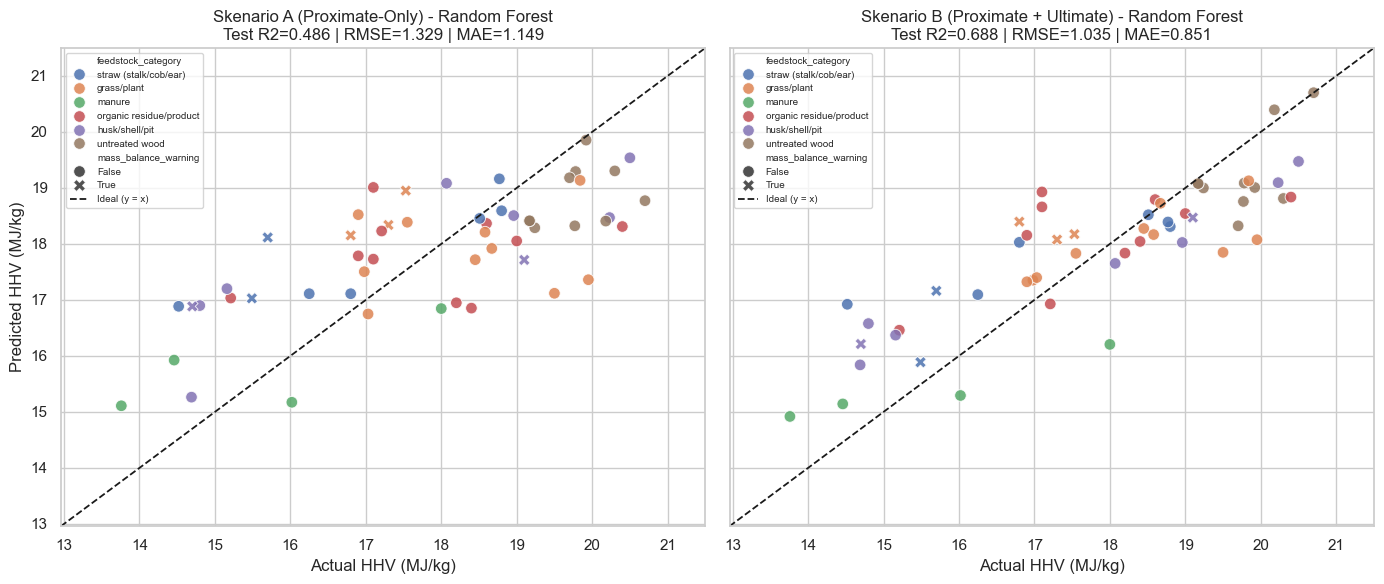

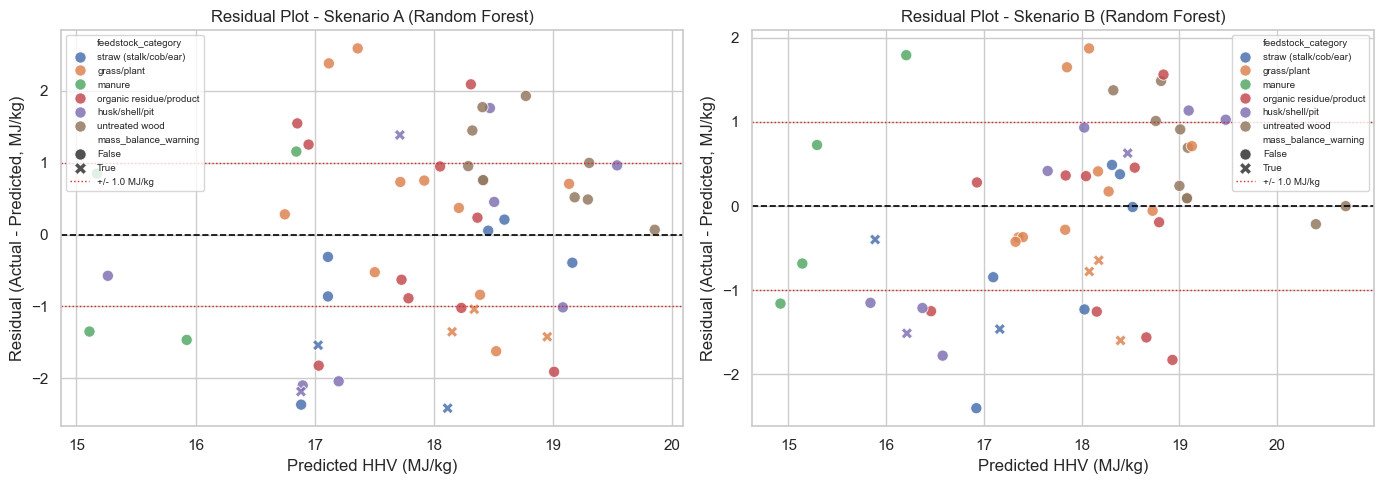

In [3]:
test_audit = df_test.copy()
test_audit["pred_a"] = res_a["test_preds"][res_a["best_algo"]]
test_audit["pred_b"] = res_b["test_preds"][res_b["best_algo"]]
test_audit["resid_a"] = test_audit["hhv_db"] - test_audit["pred_a"]
test_audit["resid_b"] = test_audit["hhv_db"] - test_audit["pred_b"]

subgroup_rows = []
subgroups = {
    "Seluruh Test Set": pd.Series(True, index=test_audit.index),
    "Tanpa Warning Neraca Massa": ~test_audit["mass_balance_warning"],
    "Dengan mass_balance_warning": test_audit["mass_balance_warning"],
    "Biomassa Tanaman/Kayu (Non-Manure)": test_audit["feedstock_category"] != "manure",
    "Kategori Manure": test_audit["feedstock_category"] == "manure",
}

for label, mask in subgroups.items():
    sub = test_audit.loc[mask]
    if len(sub) == 0:
        continue
    m_a = compute_metrics(sub["hhv_db"].values, sub["pred_a"].values)
    m_b = compute_metrics(sub["hhv_db"].values, sub["pred_b"].values)
    subgroup_rows.append({
        "Subkelompok Test Set": label,
        "n": len(sub),
        "Skenario A RMSE": m_a["rmse"],
        "Skenario A MAE": m_a["mae"],
        "Skenario B RMSE": m_b["rmse"],
        "Skenario B MAE": m_b["mae"],
    })

subgroup_df = pd.DataFrame(subgroup_rows).round(4)
display(subgroup_df)

# Grafik 1: Actual vs Predicted untuk Skenario A & B pada Internal Test Set
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
lims = [min(y_test.min(), test_audit["pred_a"].min(), test_audit["pred_b"].min()) - 0.8,
        max(y_test.max(), test_audit["pred_a"].max(), test_audit["pred_b"].max()) + 0.8]

for ax, pred_col, res_obj, title_prefix in [
    (axes[0], "pred_a", res_a, "Skenario A (Proximate-Only)"),
    (axes[1], "pred_b", res_b, "Skenario B (Proximate + Ultimate)"),
]:
    sns.scatterplot(
        data=test_audit,
        x="hhv_db",
        y=pred_col,
        hue="feedstock_category",
        style="mass_balance_warning",
        s=70,
        alpha=0.85,
        ax=ax,
    )
    ax.plot(lims, lims, "k--", linewidth=1.3, label="Ideal (y = x)")
    m_info = compute_metrics(test_audit["hhv_db"].values, test_audit[pred_col].values)
    ax.set_title(f"{title_prefix} - {res_obj['best_algo']}\nTest R2={m_info['r2']:.3f} | RMSE={m_info['rmse']:.3f} | MAE={m_info['mae']:.3f}")
    ax.set_xlabel("Actual HHV (MJ/kg)")
    ax.set_ylabel("Predicted HHV (MJ/kg)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend(fontsize=7, loc="upper left")

plt.tight_layout()
fig_avp = FIGURES_DIR / "02_internal_actual_vs_predicted.png"
plt.savefig(fig_avp, dpi=150, bbox_inches="tight")
plt.show()

# Grafik 2: Residual Plot (Residuals vs Predicted + Distribusi Residual)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred_col, resid_col, label in [
    (axes[0], "pred_a", "resid_a", f"Skenario A ({res_a['best_algo']})"),
    (axes[1], "pred_b", "resid_b", f"Skenario B ({res_b['best_algo']})"),
]:
    sns.scatterplot(
        data=test_audit,
        x=pred_col,
        y=resid_col,
        hue="feedstock_category",
        style="mass_balance_warning",
        s=65,
        alpha=0.85,
        ax=ax,
    )
    ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2)
    ax.axhline(1.0, color="#D62728", linestyle=":", linewidth=1.0, label="+/- 1.0 MJ/kg")
    ax.axhline(-1.0, color="#D62728", linestyle=":", linewidth=1.0)
    ax.set_title(f"Residual Plot - {label}")
    ax.set_xlabel("Predicted HHV (MJ/kg)")
    ax.set_ylabel("Residual (Actual - Predicted, MJ/kg)")
    ax.legend(fontsize=7, loc="best")

plt.tight_layout()
fig_res = FIGURES_DIR / "02_internal_residuals.png"
plt.savefig(fig_res, dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi audit residual:**
- Titik-titik pada Skenario B jauh lebih rapat di sekitar garis diagonal $y = x$ dan garis nol residual dibandingkan Skenario A.
- Bandingkan metrik pada subkelompok `Non-Manure` dan `Tanpa Warning Neraca Massa` terhadap keseluruhan *test set* pada tabel di atas untuk memastikan galat tidak terkonsentrasi pada kategori utama bahan bakar pembangkit.

## 4. Interpretabilitas Model Terbaik dengan SHAP (`TreeExplainer`)

**Langkah yang dikerjakan:** Menghitung nilai kontribusi fitur SHAP (*SHapley Additive exPlanations*) menggunakan `shap.TreeExplainer` pada model pohon terbaik Skenario A dan Skenario B, lalu mengekspor tiga jenis grafik untuk masing-masing skenario:
1. **SHAP Summary Plot (Beeswarm):** Menunjukkan fitur mana yang menaikkan atau menurunkan prediksi HHV.
2. **SHAP Feature Importance (Bar):** Peringkat rata-rata kontribusi absolut (`mean(|SHAP|)`) setiap fitur.
3. **SHAP Dependence Plot (`ash_db`):** Memperlihatkan titik perubahan tajam penurunan HHV ketika kadar abu meningkat melewati batas aman boiler **10%**.

**Alasan teknis:** Sesuai Project Brief Tahap 2, interpretasi SHAP menjadi bukti ilmiah bahwa keputusan model sejalan dengan prinsip termokimia pembakaran biomassa (bukan *black-box*).

[Skenario A: Proximate-Only] Backend TreeSHAP: shap.TreeExplainer | shape=(54, 3)


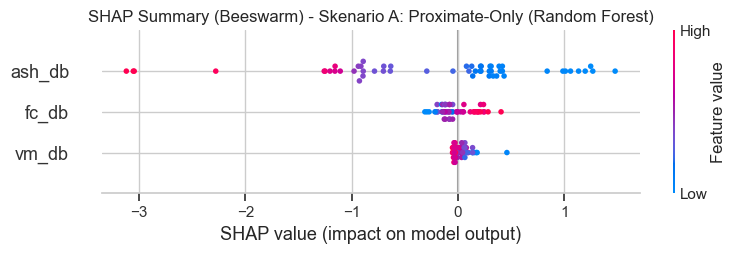

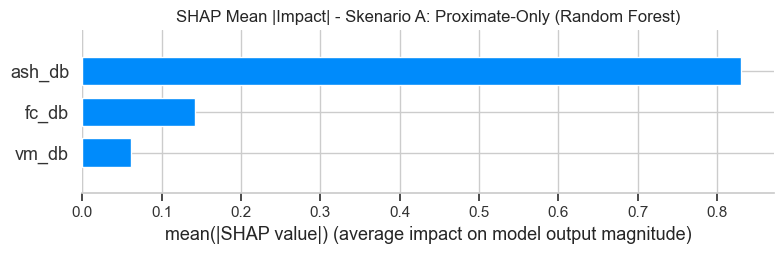

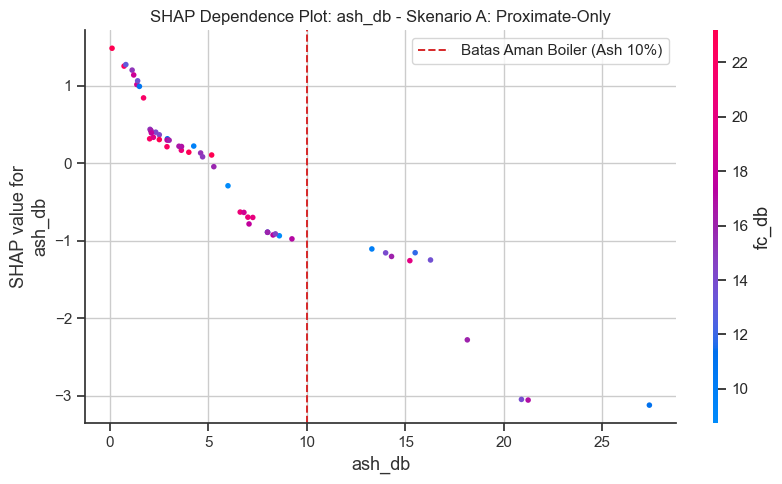

[Skenario B: Proximate + Ultimate] Backend TreeSHAP: shap.TreeExplainer | shape=(54, 8)


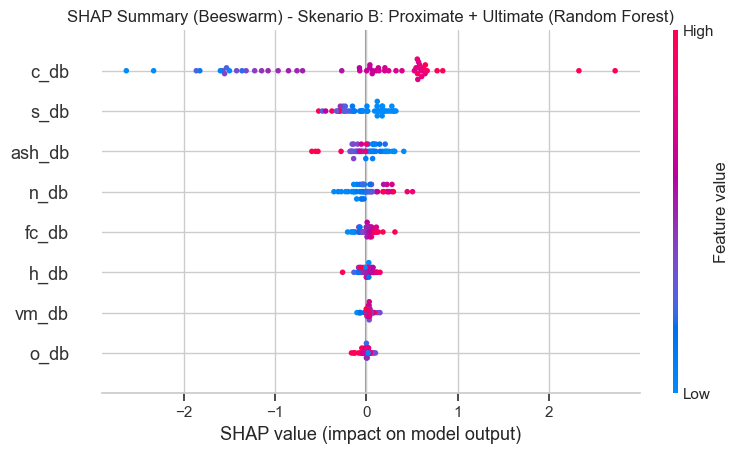

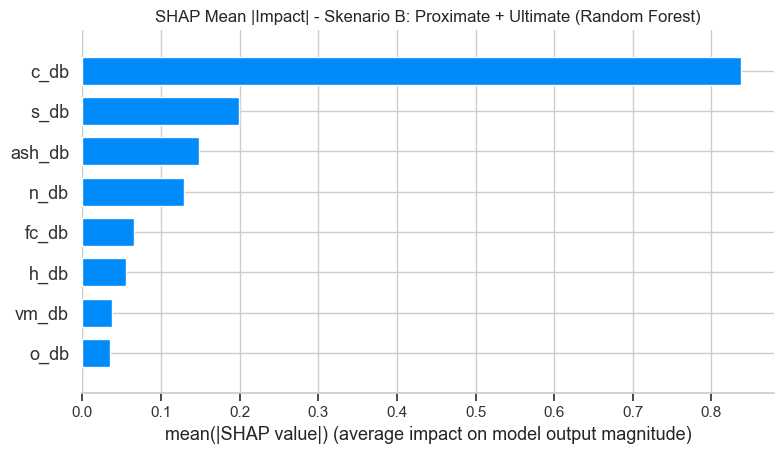

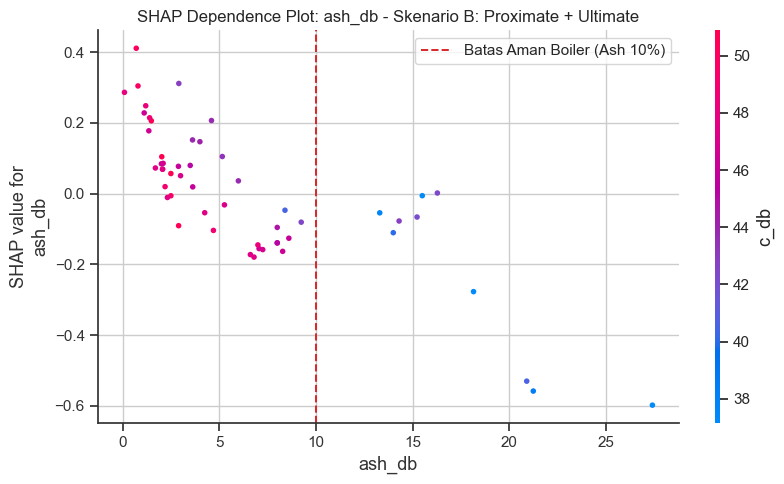

Ringkasan Mean |SHAP| Skenario A: {'ash_db': 0.8303, 'fc_db': 0.1413, 'vm_db': 0.0616}
Ringkasan Mean |SHAP| Skenario B: {'c_db': 0.8377, 's_db': 0.1986, 'ash_db': 0.1481, 'n_db': 0.1294, 'fc_db': 0.0654, 'h_db': 0.0552, 'vm_db': 0.0375, 'o_db': 0.0355}


In [4]:
def compute_tree_shap_values(tree_model, X_eval: pd.DataFrame) -> tuple[np.ndarray, str]:
    try:
        explainer = shap.TreeExplainer(tree_model)
        sv = explainer.shap_values(X_eval)
        return np.asarray(sv), "shap.TreeExplainer"
    except ValueError:
        # XGBoost >= 3.2 menyimpan base_score sebagai string array '[...]' yang belum didukung parser shap 0.49.1;
        # gunakan implementasi TreeSHAP C++ bawaan XGBoost (pred_contribs=True) yang identik secara matematis.
        contribs = tree_model.get_booster().predict(xgb.DMatrix(X_eval), pred_contribs=True)
        sv = contribs[:, :-1]
        bias = contribs[:, -1]
        assert np.allclose(sv.sum(axis=1) + bias, tree_model.predict(X_eval), atol=1e-4), "Aditivitas TreeSHAP tidak terpenuhi"
        return sv, "xgboost.DMatrix(pred_contribs=True)"

def generate_shap_plots(res_obj: dict, tag: str, title_label: str) -> dict:
    tree_model = res_obj["best_tree_estimator"]
    feats = res_obj["features"]
    X_te = df_test[feats]

    shap_values, shap_backend = compute_tree_shap_values(tree_model, X_te)
    print(f"[{title_label}] Backend TreeSHAP: {shap_backend} | shape={shap_values.shape}")

    # 1. Beeswarm summary plot
    plt.figure(figsize=(8.5, 5))
    shap.summary_plot(shap_values, X_te, show=False)
    plt.title(f"SHAP Summary (Beeswarm) - {title_label} ({res_obj['best_tree_algo']})")
    plt.tight_layout()
    p_bee = FIGURES_DIR / f"02_shap_summary_{tag}.png"
    plt.savefig(p_bee, dpi=150, bbox_inches="tight")
    plt.show()

    # 2. Mean |SHAP| bar plot
    plt.figure(figsize=(8.5, 4.5))
    shap.summary_plot(shap_values, X_te, plot_type="bar", show=False)
    plt.title(f"SHAP Mean |Impact| - {title_label} ({res_obj['best_tree_algo']})")
    plt.tight_layout()
    p_bar = FIGURES_DIR / f"02_shap_bar_{tag}.png"
    plt.savefig(p_bar, dpi=150, bbox_inches="tight")
    plt.show()

    # 3. Dependence plot untuk ash_db dengan garis vertikal batas aman boiler 10%
    fig, ax = plt.subplots(figsize=(8.5, 5))
    shap.dependence_plot("ash_db", shap_values, X_te, interaction_index="auto", ax=ax, show=False)
    ax.axvline(10.0, color="#D62728", linestyle="--", linewidth=1.4, label="Batas Aman Boiler (Ash 10%)")
    ax.set_title(f"SHAP Dependence Plot: ash_db - {title_label}")
    ax.legend(loc="best")
    plt.tight_layout()
    p_dep = FIGURES_DIR / f"02_shap_dependence_ash_{tag}.png"
    plt.savefig(p_dep, dpi=150, bbox_inches="tight")
    plt.show()

    mean_abs_shap = dict(zip(feats, np.abs(shap_values).mean(axis=0).round(4).tolist()))
    return {
        "tree_algorithm": res_obj["best_tree_algo"],
        "shap_backend": shap_backend,
        "mean_abs_shap_test": dict(sorted(mean_abs_shap.items(), key=lambda x: x[1], reverse=True)),
        "figures": [p_bee.name, p_bar.name, p_dep.name],
    }

shap_a_info = generate_shap_plots(res_a, "proximate", "Skenario A: Proximate-Only")
shap_b_info = generate_shap_plots(res_b, "full", "Skenario B: Proximate + Ultimate")

print("Ringkasan Mean |SHAP| Skenario A:", shap_a_info["mean_abs_shap_test"])
print("Ringkasan Mean |SHAP| Skenario B:", shap_b_info["mean_abs_shap_test"])

**Cara membaca dan interpretasi grafik SHAP:**
- **Beeswarm Plot:** Titik di kanan sumbu nol (`SHAP > 0`) menaikkan prediksi HHV, sedangkan titik di kiri menurunkannya. Warna merah menandakan nilai fitur tinggi dan biru nilai fitur rendah. Pada Skenario B, kadar karbon (`c_db`) dan hidrogen (`h_db`) tinggi (merah) mendorong HHV naik kuat, sedangkan kadar abu (`ash_db`) dan oksigen (`o_db`) tinggi menarik HHV turun.
- **Dependence Plot (`ash_db`):** Terlihat penurunan kontribusi nilai kalor secara konsisten ketika kadar abu meningkat melewati garis merah **10%**, mendukung aturan batas aman boiler di Project Brief.

## 5. Penyimpanan `metrics_summary.json` & Verifikasi Otomatis Tahap 2A

**Langkah yang dikerjakan:** Menyimpan ringkasan metrik CV dan *internal test* ke `outputs/metrics_summary.json`, memvalidasi ambang batas *Success Criteria* Skenario A dan B, serta memastikan seluruh file model dan gambar tersedia untuk Notebook 03.

In [5]:
best_a_row = res_a["results_df"].loc[res_a["results_df"]["Algoritma"] == res_a["best_algo"]].iloc[0].to_dict()
best_b_row = res_b["results_df"].loc[res_b["results_df"]["Algoritma"] == res_b["best_algo"]].iloc[0].to_dict()

metrics_payload = {
    "dataset": {
        "source": "data/processed/mendeley_clean.csv",
        "n_total": int(len(df_clean)),
        "n_train": int(len(df_train)),
        "n_test": int(len(df_test)),
        "split_strategy": "80/20 stratified by 4 HHV quartiles (random_state=42)",
        "cv_strategy": "5-Fold StratifiedKFold on train HHV quartiles",
    },
    "scenario_a_proximate_only": {
        "features": SCENARIO_A_FEATURES,
        "best_algorithm": res_a["best_algo"],
        "best_overall_cv_algorithm": res_a["best_overall_cv_algo"],
        "best_params": res_a["best_params_map"][res_a["best_algo"]],
        "all_models": res_a["results_df"].to_dict(orient="records"),
        "best_metrics": best_a_row,
        "shap": shap_a_info,
    },
    "scenario_b_full_features": {
        "features": SCENARIO_B_FEATURES,
        "best_algorithm": res_b["best_algo"],
        "best_overall_cv_algorithm": res_b["best_overall_cv_algo"],
        "best_params": res_b["best_params_map"][res_b["best_algo"]],
        "all_models": res_b["results_df"].to_dict(orient="records"),
        "best_metrics": best_b_row,
        "shap": shap_b_info,
    },
    "subgroup_residual_audit": subgroup_df.to_dict(orient="records"),
}

metrics_path = OUTPUTS_DIR / "metrics_summary.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

# Verifikasi file keluaran DoD Tahap 2A
required_files = [
    MODELS_DIR / "best_hhv_proximate_only.joblib",
    MODELS_DIR / "best_hhv_full_features.joblib",
    metrics_path,
    FIGURES_DIR / "02_internal_actual_vs_predicted.png",
    FIGURES_DIR / "02_internal_residuals.png",
    FIGURES_DIR / "02_shap_summary_proximate.png",
    FIGURES_DIR / "02_shap_bar_proximate.png",
    FIGURES_DIR / "02_shap_dependence_ash_proximate.png",
    FIGURES_DIR / "02_shap_summary_full.png",
    FIGURES_DIR / "02_shap_bar_full.png",
    FIGURES_DIR / "02_shap_dependence_ash_full.png",
]
for p in required_files:
    assert p.exists() and p.stat().st_size > 0, f"Artefak Tahap 2A kosong atau hilang: {p}"

# Verifikasi Success Criteria internal test yang telah dikalibrasi sesuai batas empiris Mendeley
assert best_b_row["Test_R2"] >= 0.65, f"Test R2 Skenario B ({best_b_row['Test_R2']:.4f}) di bawah 0.65"
assert best_b_row["Test_RMSE"] <= 1.10, f"Test RMSE Skenario B ({best_b_row['Test_RMSE']:.4f}) di atas 1.10 MJ/kg"
assert best_b_row["Test_MAPE_pct"] <= 6.0, f"Test MAPE Skenario B ({best_b_row['Test_MAPE_pct']:.2f}%) di atas 6.0%"
assert best_a_row["Test_R2"] >= 0.45, f"Test R2 Skenario A ({best_a_row['Test_R2']:.4f}) di bawah 0.45"
assert best_a_row["Test_RMSE"] <= 1.40, f"Test RMSE Skenario A ({best_a_row['Test_RMSE']:.4f}) di atas 1.40 MJ/kg"
assert best_a_row["Test_MAPE_pct"] <= 7.5, f"Test MAPE Skenario A ({best_a_row['Test_MAPE_pct']:.2f}%) di atas 7.5%"

print("SELURUH GERBANG VERIFIKASI TAHAP 2A LULUS:")
print(f"  - Skenario A ({res_a['best_algo']}): CV R2={best_a_row['CV_R2']:.4f}, Test R2={best_a_row['Test_R2']:.4f}, Test RMSE={best_a_row['Test_RMSE']:.4f} MJ/kg")
print(f"  - Skenario B ({res_b['best_algo']}): CV R2={best_b_row['CV_R2']:.4f}, Test R2={best_b_row['Test_R2']:.4f}, Test RMSE={best_b_row['Test_RMSE']:.4f} MJ/kg")
print("\nSerah Terima:")
print("  -> Lanjut ke notebooks/03_external_validation_and_screening.ipynb")

SELURUH GERBANG VERIFIKASI TAHAP 2A LULUS:
  - Skenario A (Random Forest): CV R2=0.3941, Test R2=0.4859, Test RMSE=1.3292 MJ/kg
  - Skenario B (Random Forest): CV R2=0.5241, Test R2=0.6884, Test RMSE=1.0349 MJ/kg

Serah Terima:
  -> Lanjut ke notebooks/03_external_validation_and_screening.ipynb
